# Used Car Price Prediction with a Neural Network (ANN) — End-to-End Notebook

**Business problem:** a used-car marketplace in India wants to show an **instant price estimate** while a seller is
filling in a listing ("cars like yours sell for about ₹4.2 lakh").

**What we build:**
1. a cleaned dataset of ~6,000 listings and a preprocessing pipeline (impute → scale → one-hot),
2. classical models (baseline, Ridge, gradient boosting) **and** neural networks: a scikit-learn `MLPRegressor`
   (runs everywhere) and a Keras functional model (needs TensorFlow),
3. an **honest comparison**: on tabular data, gradient boosting often matches or beats neural networks,
4. saved model files + `models/model_info.json` that the Flask API loads.

**Methods practised:** Batch 2 Module 05 (ANN: layers, activations, loss, overfitting, early stopping) and Module 06
(TensorFlow/Keras: functional API, `compile`, `fit`, `EarlyStopping`, saving `.keras` models), compared with the
classical regression models of Module 03.

**Expected result:** models that are far better than a "predict the average" baseline, with errors reported in lakhs
and in percent, and a clear statement of which model wins on this data. (The actual numbers of the build run are in
the outputs below and in `VERIFICATION.md`.)

**How to run:** start Jupyter from the **project root** (the folder that contains `data/`, `models/` and `backend/`):

```bash
jupyter notebook notebook/Used_Car_Price_ANN.ipynb
```

The scikit-learn part runs in a few minutes on a laptop. Cells that start with `# NO-RUN` need TensorFlow
(see the README); everything else runs without it.

In [1]:
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Make paths work whether Jupyter was started in the project root or in notebook/
if os.path.basename(os.getcwd()) == "notebook":
    os.chdir("..")
print("Working folder:", os.getcwd())
RANDOM_STATE = 42
DATA_YEAR = 2025          # listings were collected in 2025 -> car_age = 2025 - year

Working folder: /home/claude/Student_Friendly_AI_ML_Course/End_to_End_Projects/Deep_Learning_Projects/02_Used_Car_Price_ANN


## 1. Load the data and look at it

### Data dictionary

| Column | Meaning | Type |
|---|---|---|
| `car_id` | Listing identifier (not a feature) | integer |
| `brand` | Maker: Maruti, Hyundai, Tata, Mahindra, Honda, Toyota, Kia, Renault, Skoda | category |
| `model_segment` | Body type: Hatchback, Sedan, SUV | category |
| `year` | Year of manufacture (2010–2024) | integer |
| `km_driven` | Kilometres on the odometer | integer |
| `fuel` | Petrol, Diesel, CNG, Electric | category |
| `transmission` | Manual or Automatic | category |
| `owners` | Number of previous owners (1 = first owner, 4 = four or more) | integer |
| `city` | City of the listing (8 cities) | category |
| `seller_type` | Individual or Dealer | category |
| `mileage_kmpl` | Fuel efficiency in km per litre (km per kg for CNG). **Empty for electric cars** | number |
| `engine_cc` | Engine size in cubic centimetres. **Empty for electric cars** | number |
| **`price_lakhs`** | **Target**: selling price in lakh rupees (1 lakh = ₹1,00,000) | number |

The data is synthetic (generated by `data/generate_data.py` with a fixed seed) but follows realistic Indian
used-car patterns: cars lose value every year, high kilometres and many owners reduce the price, SUVs and automatics
cost more, and some brands hold their value better. See `data/DATA_DICTIONARY.md`.

In [2]:
df = pd.read_csv("data/used_cars.csv")
print("Shape:", df.shape)
df.head()

Shape: (6080, 13)


,car_id,brand,model_segment,year,km_driven,fuel,transmission,owners,city,seller_type,mileage_kmpl,engine_cc,price_lakhs
0,3323,Honda,Hatchback,2010,140700,Diesel,Manual,2,Jaipur,Individual,22.7,1200.0,1.17
1,297,Skoda,SUV,2023,15000,Petrol,Automatic,1,Bengaluru,Individual,15.5,1200.0,10.73
2,347,Renault,SUV,2013,110600,Petrol,Automatic,4,Hyderabad,Individual,10.9,1750.0,1.65
3,3008,Maruti,Hatchback,2013,146800,Petrol,Manual,2,Hyderabad,Dealer,20.0,1150.0,1.51
4,545,Maruti,Hatchback,2023,35700,Diesel,Automatic,1,Hyderabad,Dealer,24.1,1300.0,4.81


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6080 entries, 0 to 6079
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   car_id         6080 non-null   int64  
 1   brand          6080 non-null   str    
 2   model_segment  6080 non-null   str    
 3   year           6080 non-null   int64  
 4   km_driven      6080 non-null   int64  
 5   fuel           6080 non-null   str    
 6   transmission   6044 non-null   str    
 7   owners         6080 non-null   int64  
 8   city           6080 non-null   str    
 9   seller_type    6055 non-null   str    
 10  mileage_kmpl   5852 non-null   float64
 11  engine_cc      5878 non-null   float64
 12  price_lakhs    6080 non-null   float64
dtypes: float64(3), int64(4), str(6)
memory usage: 617.6 KB


In [4]:
print("Missing values per column:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nCities:", sorted(df["city"].unique()))

Missing values per column:
car_id             0
brand              0
model_segment      0
year               0
km_driven          0
fuel               0
transmission      36
owners             0
city               0
seller_type       25
mileage_kmpl     228
engine_cc        202
price_lakhs        0
dtype: int64

Duplicate rows: 80

Cities: ['Bangalore', 'Bengaluru', 'Chennai', 'Delhi', 'Hyderabad', 'Jaipur', 'Kolkata', 'Mumbai', 'Pune']


In [5]:
df.describe().round(1)

,car_id,year,km_driven,owners,mileage_kmpl,engine_cc,price_lakhs
count,6080.0,6080.0,6080.0,6080.0,5852.0,5878.0,6080.0
mean,2996.5,2017.0,113391.0,1.5,18.1,1439.9,4.5
std,1732.4,4.3,411778.2,0.7,4.2,349.9,3.2
min,1.0,2010.0,5700.0,1.0,9.2,800.0,0.3
25%,1495.8,2013.0,46775.0,1.0,14.4,1200.0,2.1
50%,2997.5,2017.0,86200.0,1.0,17.5,1350.0,3.5
75%,4496.2,2021.0,132525.0,2.0,21.0,1650.0,5.9
max,6000.0,2024.0,16310000.0,4.0,30.6,2800.0,23.4


**What we see:**
- `mileage_kmpl` and `engine_cc` are empty for some rows. Part of that is **expected** (electric cars have neither);
  the rest is sellers leaving the field blank.
- There are exact duplicate rows (the same listing posted twice).
- The city list contains both **"Bangalore" and "Bengaluru"** — the same city written two ways.
- The maximum `km_driven` is in the **millions**. No family car drives 10 million km: these are typing mistakes
  (an extra "00").

In [6]:
# How many missing mileage values are "not applicable" (electric) and how many are really missing?
print(pd.crosstab(df["fuel"], df["mileage_kmpl"].isna(), colnames=["mileage missing?"]))
print("\nLargest km_driven values:")
print(df["km_driven"].sort_values(ascending=False).head(15).to_list())

mileage missing?  False  True 
fuel                          
CNG                 426      4
Diesel             1729     17
Electric              0    157
Petrol             3697     50

Largest km_driven values:
[16310000, 11740000, 10620000, 10300000, 9780000, 8520000, 7560000, 7050000, 6790000, 6330000, 6290000, 1850000, 456700, 434000, 407500]


## 2. Clean the data

| Problem | What we do | Why |
|---|---|---|
| Duplicate listings | drop them **before** splitting | otherwise the same car can be in train *and* test |
| "Bangalore" vs "Bengaluru" | map to "Bengaluru" | one city should be one category |
| `km_driven` above 5,00,000 km | drop those rows | impossible values; we cannot know the true number |
| Missing values | **leave them** for the pipeline | the fill values (medians) must be learned from training data only |

The largest *plausible* values in the list above are around 4.5 lakh km for 12-year-old cars, followed by a jump to
18 lakh km and more. That jump is why 5,00,000 km is a sensible cut-off.

In [7]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {before - len(df)} duplicate rows")

df["city"] = df["city"].replace({"Bangalore": "Bengaluru"})

KM_LIMIT = 500_000
bad_km = df["km_driven"] > KM_LIMIT
print(f"Removed {bad_km.sum()} rows with km_driven > {KM_LIMIT:,}")
df = df[~bad_km].reset_index(drop=True)
print("Rows left:", len(df))

Removed 80 duplicate rows
Removed 12 rows with km_driven > 500,000
Rows left: 5988


## 3. Create a feature: car age

The model should learn "how old is the car", not "which calendar year". `car_age = 2025 − year` says the same thing
but keeps working next year if we update `DATA_YEAR` (a 2024 car is 1 year old today and 2 years old next year).

In [8]:
df["car_age"] = DATA_YEAR - df["year"]
df[["year", "car_age", "km_driven", "price_lakhs"]].head()

,year,car_age,km_driven,price_lakhs
0,2010,15,140700,1.17
1,2023,2,15000,10.73
2,2013,12,110600,1.65
3,2013,12,146800,1.51
4,2023,2,35700,4.81


## 4. Explore the data

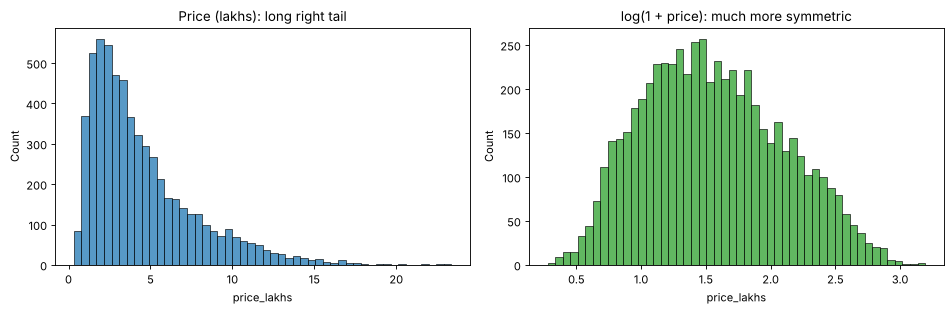

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["price_lakhs"], bins=50, ax=axes[0])
axes[0].set_title("Price (lakhs): long right tail")
sns.histplot(np.log1p(df["price_lakhs"]), bins=50, ax=axes[1], color="tab:green")
axes[1].set_title("log(1 + price): much more symmetric")
plt.tight_layout()

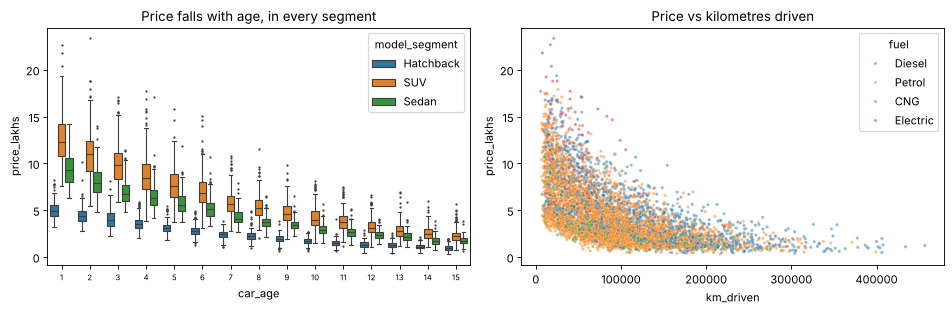

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="car_age", y="price_lakhs", hue="model_segment", ax=axes[0], fliersize=1)
axes[0].set_title("Price falls with age, in every segment")
axes[0].tick_params(axis="x", labelsize=7)
sns.scatterplot(data=df, x="km_driven", y="price_lakhs", hue="fuel", s=8, alpha=0.5, ax=axes[1])
axes[1].set_title("Price vs kilometres driven")
plt.tight_layout()

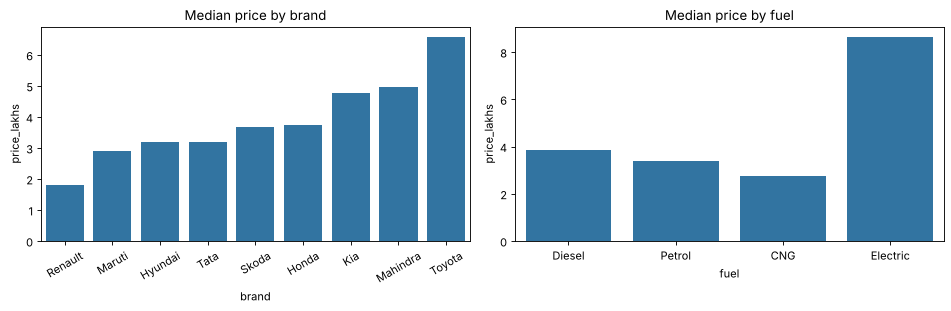

In [11]:
# Median price by brand and by fuel type
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
order = df.groupby("brand")["price_lakhs"].median().sort_values().index
sns.barplot(data=df, x="brand", y="price_lakhs", order=order, estimator=np.median, errorbar=None, ax=axes[0])
axes[0].set_title("Median price by brand"); axes[0].tick_params(axis="x", rotation=30)
sns.barplot(data=df, x="fuel", y="price_lakhs", estimator=np.median, errorbar=None, ax=axes[1])
axes[1].set_title("Median price by fuel")
plt.tight_layout()

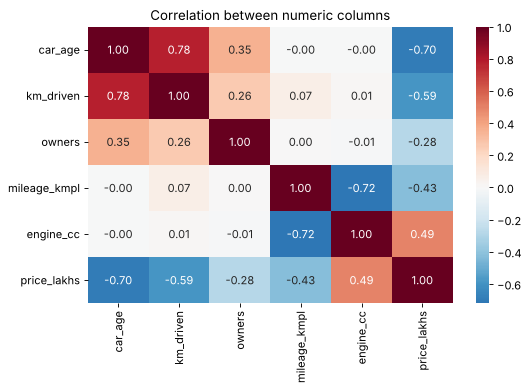

In [12]:
numeric_cols = ["car_age", "km_driven", "owners", "mileage_kmpl", "engine_cc", "price_lakhs"]
plt.figure(figsize=(7, 5))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlation between numeric columns")
plt.tight_layout()

**What to notice:**
- Price has a **long right tail**: most cars cost a few lakhs, a few SUVs cost much more. After `log(1 + price)` the
  distribution looks much more symmetric. We will test whether predicting the log helps (section 7).
- Age is the strongest single signal (strong negative correlation with price). `km_driven` is also negative, but
  it is strongly correlated with age, because older cars have driven more.
- Bigger engines mean pricier cars (SUVs), and bigger engines give lower mileage — features are related to each other.

## 5. Choose features and target, then split

We use `car_age` instead of `year`, and leave out `car_id` (just a label). 20% of the cars are kept aside as a
**test set** that no model sees during training or model selection.

In [13]:
NUMERIC = ["car_age", "km_driven", "owners", "mileage_kmpl", "engine_cc"]
CATEGORICAL = ["brand", "model_segment", "fuel", "transmission", "city", "seller_type"]
TARGET = "price_lakhs"

X = df[NUMERIC + CATEGORICAL]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (4790, 11)  Test: (1198, 11)


## 6. The preprocessing pipeline

Neural networks are **very sensitive to the scale of their inputs**: `km_driven` (tens of thousands) and `owners`
(1–4) must be put on a similar scale, otherwise training is slow and unstable. Trees do not care, but it does not
hurt them either, so all models share one pipeline:

- numeric columns: fill missing values with the training **median**, add a 0/1 "was missing" column
  (`add_indicator=True` — useful because missing mileage usually means *electric*), then **standardise**
  (mean 0, standard deviation 1),
- categorical columns: fill missing with the most frequent value, then **one-hot encode**
  (`handle_unknown="ignore"` so an unseen value does not crash prediction).

In [14]:
def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                          ("scale", StandardScaler())]), NUMERIC),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), CATEGORICAL),
    ])

prep_demo = make_preprocessor().fit(X_train)
print("Columns going into the models:", prep_demo.transform(X_train.head()).shape[1])
print(list(prep_demo.get_feature_names_out())[:12], "...")

Columns going into the models: 35
['num__car_age', 'num__km_driven', 'num__owners', 'num__mileage_kmpl', 'num__engine_cc', 'num__missingindicator_mileage_kmpl', 'num__missingindicator_engine_cc', 'cat__brand_Honda', 'cat__brand_Hyundai', 'cat__brand_Kia', 'cat__brand_Mahindra', 'cat__brand_Maruti'] ...


## 7. Experiment: predict the price or log(price)?

Errors on expensive cars are large in lakhs, so a model trained on raw prices focuses on the expensive cars.
Training on `log(1 + price)` makes the model care about **percentage** errors instead, which suits prices.
`TransformedTargetRegressor` does the log before training and converts predictions back with `exp(x) − 1`,
so the metrics are still in lakhs.

We compare with **3-fold cross-validation on the training set only** (the test set stays untouched).

The neural network here is scikit-learn's `MLPRegressor` — a fully connected ANN: 2 hidden layers with 64 and 32
ReLU neurons, Adam optimiser, a little L2 penalty (`alpha`), and **early stopping**: 10% of the training data is held
out and training stops when the validation score has not improved for 20 epochs.

In [15]:
def make_mlp():
    return MLPRegressor(hidden_layer_sizes=(64, 32), activation="relu", solver="adam", alpha=1e-3,
                        learning_rate_init=1e-3, batch_size=64, max_iter=500,
                        early_stopping=True, validation_fraction=0.1, n_iter_no_change=20,
                        random_state=RANDOM_STATE)

def with_log_target(model):
    return TransformedTargetRegressor(regressor=model, func=np.log1p, inverse_func=np.expm1)

cv3 = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, make in [("Ridge", lambda: Ridge(alpha=1.0)),
                   ("Gradient Boosting", lambda: HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
                   ("MLP (ANN)", make_mlp)]:
    for target, model in [("price", make()), ("log(price)", with_log_target(make()))]:
        pipe = Pipeline([("prep", make_preprocessor()), ("model", model)])
        mae = -cross_val_score(pipe, X_train, y_train, cv=cv3, scoring="neg_mean_absolute_error")
        rows.append({"model": name, "target": target, "CV MAE (lakhs)": mae.mean()})
log_experiment = pd.DataFrame(rows).pivot(index="model", columns="target", values="CV MAE (lakhs)").round(3)
log_experiment

target,log(price),price
model,,
Gradient Boosting,0.392,0.409
MLP (ANN),0.405,0.393
Ridge,0.451,0.937


**Reading the table:** the log target helps **Ridge** enormously — prices fall by a roughly constant *percentage*
per year of age, which is a straight line only after taking the log (its CV MAE roughly halves). For the two flexible
models the difference is small — a few hundredths of a lakh: gradient boosting gains a little, and the MLP is even
slightly *worse* with the log target in this run. They can learn curved relationships themselves.

We still use the log target for all three models from now on: it makes the models care about **percentage** errors
(a ₹50,000 mistake matters more on a ₹2 lakh car than on a ₹15 lakh car), it can never predict a negative price, and
it keeps the comparison fair because every model gets the same setup.

## 8. Train the baseline and the models, evaluate on the test set

- **MAE** — average error in lakhs (₹1 lakh = ₹1,00,000). Easy to explain to a seller.
- **MAPE** — average error in **percent** of the true price. A 0.5-lakh error is big on a ₹2 lakh hatchback and small
  on a ₹15 lakh SUV; MAPE treats them fairly.
- **R²** — share of the price variation explained (1 = perfect, 0 = no better than the average).

In [16]:
def scores(name, y_true, pred, seconds):
    return {"model": name,
            "MAE (lakhs)": mean_absolute_error(y_true, pred),
            "MAPE (%)": np.mean(np.abs(y_true - pred) / y_true) * 100,
            "R2": r2_score(y_true, pred),
            "train time (s)": seconds}

candidates = {
    "Baseline (mean)": DummyRegressor(strategy="mean"),
    "Ridge (log target)": with_log_target(Ridge(alpha=1.0)),
    "Gradient Boosting (log target)": with_log_target(HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
    "MLP ANN (log target)": with_log_target(make_mlp()),
}
fitted, rows = {}, []
for name, model in candidates.items():
    start = time.time()
    pipe = Pipeline([("prep", make_preprocessor()), ("model", model)]).fit(X_train, y_train)
    fitted[name] = pipe
    rows.append(scores(name, y_test, pipe.predict(X_test), time.time() - start))

results = pd.DataFrame(rows).set_index("model").round(3)
results

,MAE (lakhs),MAPE (%),R2,train time (s)
model,,,,
Baseline (mean),2.555,94.452,-0.000,0.028
Ridge (log target),0.470,11.250,0.947,0.033
Gradient Boosting (log target),0.374,8.680,0.965,0.528
MLP ANN (log target),0.389,8.966,0.962,2.444


Epochs run: 66 of max 500
Best validation R2 (on log price): 0.9744


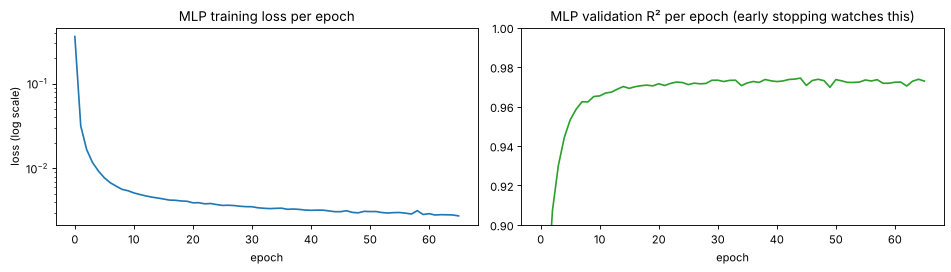

In [17]:
# How long did the neural network train, and did early stopping kick in?
mlp = fitted["MLP ANN (log target)"].named_steps["model"].regressor_
print("Epochs run:", mlp.n_iter_, "of max", mlp.max_iter)
print("Best validation R2 (on log price):", round(mlp.best_validation_score_, 4))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(mlp.loss_curve_)
axes[0].set_title("MLP training loss per epoch"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss (log scale)")
axes[0].set_yscale("log")
axes[1].plot(mlp.validation_scores_, color="tab:green")
axes[1].set_title("MLP validation R² per epoch (early stopping watches this)"); axes[1].set_xlabel("epoch")
axes[1].set_ylim(0.9, 1.0)
plt.tight_layout()

**Training curves:** the training loss drops fast in the first epochs and then flattens. The validation R² rises
quickly and then levels off; early stopping ended training once it stopped improving for 20 epochs, so we did not
have to guess the number of epochs.

## 9. Check the result is stable with cross-validation

One test split can be lucky. 5-fold cross-validation on the training set shows the **average** error and how much it
varies between folds. If two models' averages differ by less than their standard deviations, treat them as tied.

In [18]:
cv5 = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name in ["Ridge (log target)", "Gradient Boosting (log target)", "MLP ANN (log target)"]:
    pipe = Pipeline([("prep", make_preprocessor()), ("model", candidates[name])])
    mae = -cross_val_score(pipe, X_train, y_train, cv=cv5, scoring="neg_mean_absolute_error")
    cv_rows.append({"model": name, "CV MAE mean": mae.mean(), "CV MAE std": mae.std()})
cv_results = pd.DataFrame(cv_rows).set_index("model").round(3)
cv_results

,CV MAE mean,CV MAE std
model,,
Ridge (log target),0.450,0.019
Gradient Boosting (log target),0.390,0.004
MLP ANN (log target),0.396,0.008


In [19]:
ann_name, gb_name = "MLP ANN (log target)", "Gradient Boosting (log target)"
diff = cv_results.loc[ann_name, "CV MAE mean"] - cv_results.loc[gb_name, "CV MAE mean"]
spread = max(cv_results.loc[ann_name, "CV MAE std"], cv_results.loc[gb_name, "CV MAE std"])
print(f"ANN minus gradient boosting, CV MAE: {diff:+.3f} lakhs (fold-to-fold spread about {spread:.3f})")
if abs(diff) <= spread:
    print("-> Within the noise: the ANN and gradient boosting are effectively tied on this data.")
elif diff < 0:
    print("-> The ANN is clearly better on this data.")
else:
    print("-> Gradient boosting is clearly better on this data.")
print(f"Baseline test MAE for reference: {results.loc['Baseline (mean)', 'MAE (lakhs)']:.2f} lakhs")

ANN minus gradient boosting, CV MAE: +0.006 lakhs (fold-to-fold spread about 0.008)
-> Within the noise: the ANN and gradient boosting are effectively tied on this data.
Baseline test MAE for reference: 2.56 lakhs


### The honest comparison: ANN vs gradient boosting on tabular data

The printout above is the verdict for **this** data: on the test set gradient boosting has a slightly lower MAE than
the MLP, but the gap is smaller than the fold-to-fold variation in cross-validation, so the two are **tied** —
and both are far better than the baseline and clearly better than Ridge. In practice:

- On **tabular data** (rows and columns like this), **gradient boosted trees are usually as good as or better than
  neural networks**, train in seconds, need almost no tuning and do not need scaling.
- Neural networks earn their place when data is **images, audio, text**, or very large tabular datasets with
  learned embeddings. Here the MLP did well because the data has smooth, multiplicative patterns — but it needed
  scaling, a log target, early stopping and more training time to get there.
- Ridge, a straight line on log price, is a strong, explainable runner-up — always try a simple model first.

The API therefore returns **both** the ANN estimate and the gradient boosting estimate, so users (and you) can see
when they agree.

## 10. Deep learning with TensorFlow / Keras (Module 06)

The cells below build the same idea as a **Keras functional model**. To keep training and the API identical, Keras
receives the **output of the same fitted scikit-learn preprocessor** (scaled numbers + one-hot columns), and it is
trained on `log(1 + price)`.

> **These cells start with `# NO-RUN`.** TensorFlow was not available where this notebook was built, so the cells
> were only syntax-checked and have no outputs. They are correct Keras 3 code: install TensorFlow
> (`pip install -r requirements-tf.txt`, Python 3.10–3.12) and run them yourself. The last one saves
> `models/car_price_ann.keras`; when that file exists and TensorFlow is installed, the API uses it automatically.

First, a **runnable** cell fits the preprocessor on the training data and saves it, because both Keras and the API
need exactly this fitted object.

In [20]:
preprocessor = make_preprocessor().fit(X_train)
X_train_ready = preprocessor.transform(X_train).astype("float32")
X_test_ready = preprocessor.transform(X_test).astype("float32")
y_train_log = np.log1p(y_train.to_numpy()).astype("float32")

os.makedirs("models", exist_ok=True)
joblib.dump(preprocessor, "models/preprocessor.joblib")
print("Keras input shape:", X_train_ready.shape, "-> saved models/preprocessor.joblib")

Keras input shape: (4790, 35) -> saved models/preprocessor.joblib


In [ ]:
# NO-RUN  (needs TensorFlow: pip install -r requirements-tf.txt)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(RANDOM_STATE)   # same starting weights every run
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

In [ ]:
# NO-RUN
# Functional API: describe the path from inputs to output, then wrap it in a Model
inputs = keras.Input(shape=(X_train_ready.shape[1],), name="car_features")
x = layers.Dense(64, activation="relu")(inputs)      # hidden layer 1
x = layers.Dropout(0.1)(x)                           # randomly switch off 10% of neurons while training
x = layers.Dense(32, activation="relu")(x)           # hidden layer 2
outputs = layers.Dense(1, name="log_price")(x)       # ONE number, no activation: regression output
ann = keras.Model(inputs=inputs, outputs=outputs, name="car_price_ann")

ann.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
            loss="mse",                               # mean squared error on log(price)
            metrics=["mae"])
ann.summary()

In [ ]:
# NO-RUN
# Stop when the validation loss has not improved for 20 epochs, and keep the best weights
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)
history = ann.fit(X_train_ready, y_train_log, validation_split=0.1, epochs=500, batch_size=64,
                  callbacks=[early_stop], verbose=0)
print("Epochs run:", len(history.history["loss"]))

# Training curves: validation loss rising while training loss falls = overfitting
pd.DataFrame(history.history)[["loss", "val_loss"]].plot(figsize=(6, 3), logy=True,
                                                         title="Keras ANN: loss per epoch (log price)")
plt.xlabel("epoch")
plt.tight_layout()

In [ ]:
# NO-RUN
# Evaluate in lakhs: undo the log with expm1, then compare with the scikit-learn table
keras_pred = np.expm1(ann.predict(X_test_ready, verbose=0).ravel())
keras_row = scores("Keras ANN (log target)", y_test, keras_pred, float("nan"))
print(pd.concat([results, pd.DataFrame([keras_row]).set_index("model").round(3)]))

ann.save("models/car_price_ann.keras")                 # Keras 3 native format (one file)
reloaded_ann = keras.models.load_model("models/car_price_ann.keras")
assert np.allclose(reloaded_ann.predict(X_test_ready[:5], verbose=0), ann.predict(X_test_ready[:5], verbose=0),
                   atol=1e-5)
print("Saved models/car_price_ann.keras and reloaded it.")

**When you run these cells:** expect the Keras ANN to land close to the scikit-learn MLP (same architecture idea,
same inputs). The exact numbers differ between computers because of random initialisation. If the Keras model is
worse than gradient boosting, that is a normal and useful finding, not a bug.

> **Alternative:** Keras can also do the preprocessing itself with `layers.Normalization` (for numbers) and
> `layers.StringLookup` + one-hot (for categories) inside the model. That makes the `.keras` file self-contained,
> but the API would then need different input code. Using the shared scikit-learn preprocessor keeps this project
> simpler and guarantees all models see identical inputs.

## 11. Error analysis: where does the ANN make mistakes?

In [21]:
ann_model = fitted[ann_name]
gb_model = fitted[gb_name]
analysis = X_test.copy()
analysis["actual"] = y_test
analysis["ann_pred"] = ann_model.predict(X_test)
analysis["gb_pred"] = gb_model.predict(X_test)
analysis["ann_abs_err"] = (analysis["actual"] - analysis["ann_pred"]).abs()
analysis["gb_abs_err"] = (analysis["actual"] - analysis["gb_pred"]).abs()
analysis["ann_pct_err"] = analysis["ann_abs_err"] / analysis["actual"] * 100

by_segment = analysis.groupby("model_segment").agg(
    cars=("actual", "size"), median_price=("actual", "median"),
    ANN_MAE=("ann_abs_err", "mean"), GB_MAE=("gb_abs_err", "mean"), ANN_MAPE=("ann_pct_err", "mean")).round(2)
by_segment

,cars,median_price,ANN_MAE,GB_MAE,ANN_MAPE
model_segment,,,,,
Hatchback,430,2.12,0.22,0.22,9.78
SUV,503,5.50,0.53,0.49,8.45
Sedan,265,3.74,0.40,0.40,8.63


In [22]:
by_fuel = analysis.groupby("fuel").agg(
    cars=("actual", "size"), ANN_MAE=("ann_abs_err", "mean"), GB_MAE=("gb_abs_err", "mean"),
    ANN_MAPE=("ann_pct_err", "mean")).round(2)
by_fuel

,cars,ANN_MAE,GB_MAE,ANN_MAPE
fuel,,,,
CNG,76,0.23,0.25,8.62
Diesel,329,0.41,0.40,9.25
Electric,29,1.40,1.11,14.01
Petrol,764,0.36,0.35,8.69


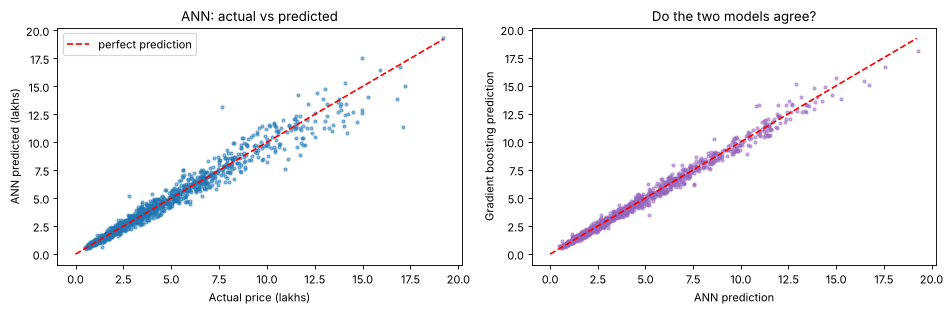

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(analysis["actual"], analysis["ann_pred"], s=8, alpha=0.5)
lims = [0, analysis["actual"].max()]
axes[0].plot(lims, lims, "r--", label="perfect prediction")
axes[0].set_xlabel("Actual price (lakhs)"); axes[0].set_ylabel("ANN predicted (lakhs)")
axes[0].set_title("ANN: actual vs predicted"); axes[0].legend()
axes[1].scatter(analysis["ann_pred"], analysis["gb_pred"], s=8, alpha=0.5, color="tab:purple")
axes[1].plot(lims, lims, "r--")
axes[1].set_xlabel("ANN prediction"); axes[1].set_ylabel("Gradient boosting prediction")
axes[1].set_title("Do the two models agree?")
plt.tight_layout()

**Reading the tables and plots:**
- Error **in lakhs** is largest for SUVs and smallest for hatchbacks, simply because SUVs cost more. The **percentage**
  error (MAPE) is much more similar across segments — a good sign that the log target worked.
- **Electric cars** are the weak spot: they are the smallest group (a few dozen test cars) and have a clearly higher
  percentage error than petrol, diesel and CNG cars for both models. Few training examples → less reliable estimates.
- The two models agree closely for most cars (points near the red line in the right plot). Where they disagree,
  the listing is unusual, and a human check is a good idea.

Because the error grows with the price, the API shows a **percentage range**: prediction ± the ANN's test MAPE.

## 12. Test new example listings and edge cases

In [24]:
new_cars = pd.DataFrame([
    # a typical 5-year-old petrol hatchback
    {"brand": "Maruti", "model_segment": "Hatchback", "car_age": 5, "km_driven": 45000, "fuel": "Petrol",
     "transmission": "Manual", "owners": 1, "city": "Pune", "seller_type": "Individual",
     "mileage_kmpl": 21.0, "engine_cc": 1200.0},
    # same car, but 3 owners and twice the kilometres
    {"brand": "Maruti", "model_segment": "Hatchback", "car_age": 5, "km_driven": 90000, "fuel": "Petrol",
     "transmission": "Manual", "owners": 3, "city": "Pune", "seller_type": "Individual",
     "mileage_kmpl": 21.0, "engine_cc": 1200.0},
    # a 2-year-old automatic diesel SUV sold by a dealer
    {"brand": "Toyota", "model_segment": "SUV", "car_age": 2, "km_driven": 30000, "fuel": "Diesel",
     "transmission": "Automatic", "owners": 1, "city": "Mumbai", "seller_type": "Dealer",
     "mileage_kmpl": 15.0, "engine_cc": 2400.0},
    # an electric SUV: no mileage, no engine size (the pipeline fills and flags them)
    {"brand": "Tata", "model_segment": "SUV", "car_age": 2, "km_driven": 25000, "fuel": "Electric",
     "transmission": "Automatic", "owners": 1, "city": "Bengaluru", "seller_type": "Individual",
     "mileage_kmpl": np.nan, "engine_cc": np.nan},
    # an old diesel sedan in Delhi (old diesels lose a lot of value there)
    {"brand": "Hyundai", "model_segment": "Sedan", "car_age": 12, "km_driven": 160000, "fuel": "Diesel",
     "transmission": "Manual", "owners": 2, "city": "Delhi", "seller_type": "Individual",
     "mileage_kmpl": 20.0, "engine_cc": 1600.0},
    # the same old diesel sedan in Chennai
    {"brand": "Hyundai", "model_segment": "Sedan", "car_age": 12, "km_driven": 160000, "fuel": "Diesel",
     "transmission": "Manual", "owners": 2, "city": "Chennai", "seller_type": "Individual",
     "mileage_kmpl": 20.0, "engine_cc": 1600.0},
])
new_cars["ANN (lakhs)"] = ann_model.predict(new_cars[NUMERIC + CATEGORICAL]).round(2)
new_cars["Boosting (lakhs)"] = gb_model.predict(new_cars[NUMERIC + CATEGORICAL]).round(2)
new_cars[["brand", "model_segment", "car_age", "km_driven", "owners", "fuel", "city", "ANN (lakhs)", "Boosting (lakhs)"]]

,brand,model_segment,car_age,km_driven,owners,fuel,city,ANN (lakhs),Boosting (lakhs)
0,Maruti,Hatchback,5,45000,1,Petrol,Pune,3.07,3.10
1,Maruti,Hatchback,5,90000,3,Petrol,Pune,2.64,2.55
2,Toyota,SUV,2,30000,1,Diesel,Mumbai,20.71,19.50
3,Tata,SUV,2,25000,1,Electric,Bengaluru,13.33,14.16
4,Hyundai,Sedan,12,160000,2,Diesel,Delhi,1.97,1.84
5,Hyundai,Sedan,12,160000,2,Diesel,Chennai,2.49,2.47


**Sanity checks to read from the table:**
- Doubling the kilometres and adding owners lowers the hatchback's price (rows 1 → 2).
- The nearly new Toyota diesel automatic SUV is by far the most expensive car.
- The electric SUV gets a prediction even though mileage and engine size are empty — the "was missing" indicator
  columns and `fuel = Electric` tell the model what kind of car it is.
- Rows 5 and 6 are the same 12-year-old diesel sedan in Delhi and in Chennai. Both models price the Delhi car
  noticeably lower: they learned the **interaction** "old + diesel + Delhi = cheaper" (in the data, old diesels cannot
  be registered in Delhi). Ridge, a sum of separate effects, cannot learn such a combined rule on its own.

The API adds checks the notebook does not: it rejects unknown brands/cities, values outside the training ranges,
and electric cars older than the oldest electric car in the data.

## 13. Save the models and the information the API needs

- `models/car_price_mlp_sklearn.joblib` — the **verified ANN fallback**: the whole pipeline (fitted preprocessing +
  MLP + log/exp target transform). The API sends raw values and gets lakhs back.
- `models/car_price_gb.joblib` — the gradient boosting pipeline, returned next to the ANN for comparison.
- `models/preprocessor.joblib` — saved in section 10, needed by the Keras model.
- `models/model_info.json` — allowed values, ranges and test metrics for validation and the price range.

In [25]:
joblib.dump(ann_model, "models/car_price_mlp_sklearn.joblib")
joblib.dump(gb_model, "models/car_price_gb.joblib")

def metric_dict(name):
    r = results.loc[name]
    return {"MAE_lakhs": round(float(r["MAE (lakhs)"]), 3), "MAPE_pct": round(float(r["MAPE (%)"]), 2),
            "R2": round(float(r["R2"]), 4)}

model_info = {
    "data_year": DATA_YEAR,
    "target": TARGET,
    "target_transform": "log1p (predictions are converted back with expm1)",
    "numeric_features": NUMERIC,
    "categorical_features": CATEGORICAL,
    "categories": {c: sorted(df[c].dropna().unique().tolist()) for c in CATEGORICAL},
    "numeric_ranges": {c: [float(df[c].min()), float(df[c].max())] for c in NUMERIC},
    "year_range": [int(df["year"].min()), int(df["year"].max())],
    "electric_min_year": int(df.loc[df["fuel"] == "Electric", "year"].min()),
    "city_aliases": {"Bangalore": "Bengaluru"},
    "models": {
        "ann_sklearn": {"name": "MLPRegressor ANN (scikit-learn)", "file": "car_price_mlp_sklearn.joblib",
                        "test_metrics": metric_dict(ann_name)},
        "ann_keras": {"name": "Keras ANN (TensorFlow)", "file": "car_price_ann.keras",
                      "preprocessor": "preprocessor.joblib", "output": "log1p(price_lakhs)"},
        "gradient_boosting": {"name": "HistGradientBoosting", "file": "car_price_gb.joblib",
                              "test_metrics": metric_dict(gb_name)},
    },
    "baseline_test_mae": round(float(results.loc["Baseline (mean)", "MAE (lakhs)"]), 3),
    "train_rows": int(len(X_train)),
}
with open("models/model_info.json", "w") as f:
    json.dump(model_info, f, indent=2)
print(json.dumps({k: v.get("test_metrics") for k, v in model_info["models"].items()}, indent=2))
print("numeric ranges:", model_info["numeric_ranges"])
print(sorted(os.listdir("models")))

{
  "ann_sklearn": {
    "MAE_lakhs": 0.389,
    "MAPE_pct": 8.97,
    "R2": 0.962
  },
  "ann_keras": null,
  "gradient_boosting": {
    "MAE_lakhs": 0.374,
    "MAPE_pct": 8.68,
    "R2": 0.965
  }
}
numeric ranges: {'car_age': [1.0, 15.0], 'km_driven': [5700.0, 456700.0], 'owners': [1.0, 4.0], 'mileage_kmpl': [9.2, 30.6], 'engine_cc': [800.0, 2800.0]}
['car_price_gb.joblib', 'car_price_mlp_sklearn.joblib', 'model_info.json', 'preprocessor.joblib']


In [26]:
# Reload from disk exactly as the API will, and check the predictions match
reloaded = joblib.load("models/car_price_mlp_sklearn.joblib")
sample = X_test.head(5)
assert np.allclose(reloaded.predict(sample), ann_model.predict(sample))
assert np.allclose(joblib.load("models/car_price_gb.joblib").predict(sample), gb_model.predict(sample))
print("Reloaded models give identical predictions.")

Reloaded models give identical predictions.


## 14. Limitations and possible improvements

- **Synthetic data.** The patterns are realistic but invented. Real listings have model names (Swift vs Baleno),
  variants, accident history and photos — all of which move the price.
- **Listing price ≠ selling price.** Real marketplaces see asking prices, which are usually higher than final deals.
- **Out-of-range inputs.** The models have only seen cars up to 15 years old and 5 lakh km. Trees cannot extrapolate,
  and neural networks extrapolate *unpredictably*, so the API refuses values outside the training ranges.
- **Few electric cars.** Predictions for EVs rest on a small group; treat them with extra care.
- **Prices drift.** New-car prices and fuel policies change, so the model must be retrained regularly
  (and `DATA_YEAR` updated).
- **Improvements to try:** tune the MLP (layers, `alpha`, learning rate) with `RandomizedSearchCV`; use Keras
  embeddings for `brand` and `city`; add a `km_per_year` feature; predict a range directly with quantile regression
  (`HistGradientBoostingRegressor(loss="quantile")`).

**Next step:** start the Flask API in `backend/` (see the project README). It loads the files saved above.